# Análisis exploratorio de datos

Contentesta las siguientes preguntas escribiendo el código de Python necesario para encontrar las respuestas o producir las gráficas necesarias

---


In [11]:
# No mostrar advertencias
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el conjunto de datos
df = pd.read_csv('data/retailmax.csv')

display(df.head())

print("Columnas del conjunto de datos: ")
print(df.columns.tolist())

print("Dimensiones del conjunto de datos: ")
print(df.shape)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Columnas del conjunto de datos: 
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Dimensiones del conjunto de datos: 
(200, 5)


### 1. ¿Cuál es la distribución de edades de los clientes?
- **Objetivo**: Comprender la distribución de las edades en el conjunto de datos.
- **Respuesta esperada**: Un histograma de la columna Age.

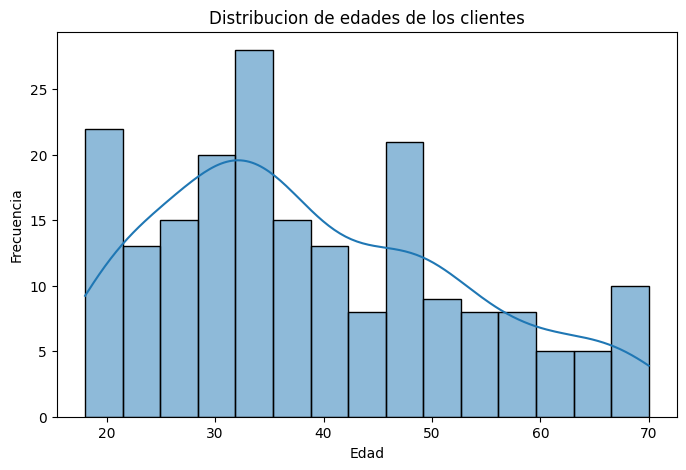

In [12]:
# tu código aquí
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', bins=15, kde=True)
plt.title('Distribucion de edades de los clientes')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

### 2. ¿Existen diferencias significativas en los ingresos anuales entre hombres y mujeres?
- **Objetivo**: Comparar la distribución de ingresos anuales entre géneros.
- **Respuesta esperada**: Una gráfica de cajas (boxplot) que muestre la distribución de Annual Income (k$) por género.

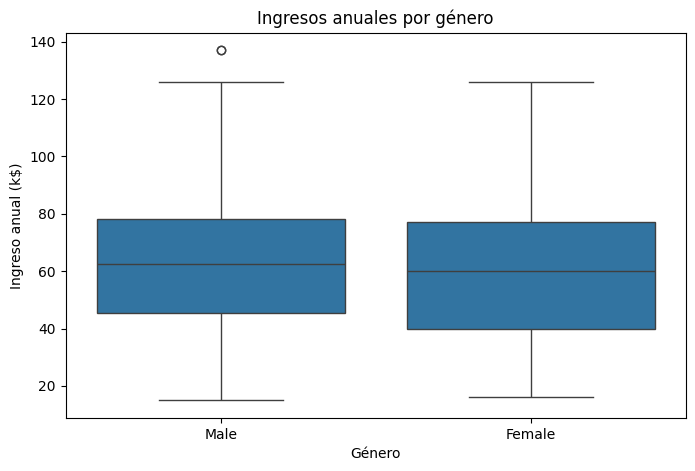

In [13]:
# tu código aquí
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Gender', y='Annual Income (k$)')
plt.title('Ingresos anuales por género')
plt.xlabel('Género')
plt.ylabel('Ingreso anual (k$)')
plt.show()


### 3. ¿Cómo se distribuye la puntuación de gasto (Spending Score) entre los diferentes rangos de edad?
- **Objetivo**: Analizar la relación entre la edad y la puntuación de gasto.
- **Respuesta esperada**: Una gráfica de dispersión (scatter plot) o un gráfico de cajas que compare la Spending Score (1-100) con diferentes grupos de edad.

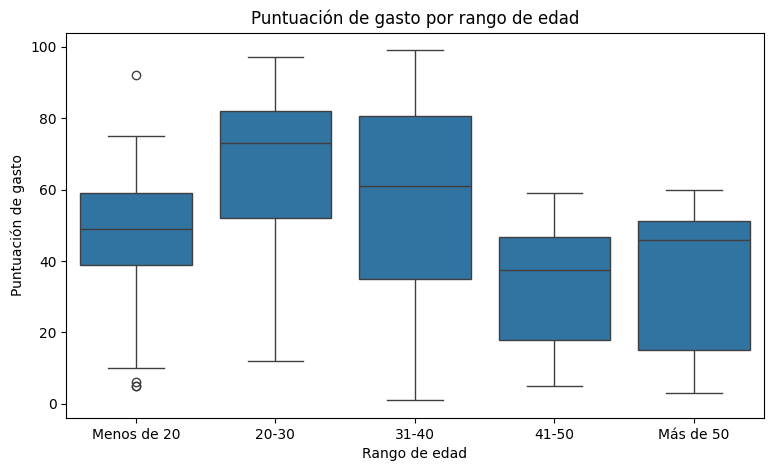

In [14]:
# tu código aquí
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 20, 30, 40, 50, 100],
    labels=['Menos de 20', '20-30', '31-40', '41-50', 'Más de 50']
)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Age Group', y='Spending Score (1-100)')
plt.title('Puntuación de gasto por rango de edad')
plt.xlabel('Rango de edad')
plt.ylabel('Puntuación de gasto')
plt.show()

### 4. ¿Cuál es la correlación entre el ingreso anual y la puntuación de gasto?
- **Objetivo**: Identificar si existe una relación lineal entre el ingreso y el gasto.
- **Respuesta esperada**: Una gráfica de dispersión y el cálculo del coeficiente de correlación entre Annual Income (k$) y Spending Score (1-100).

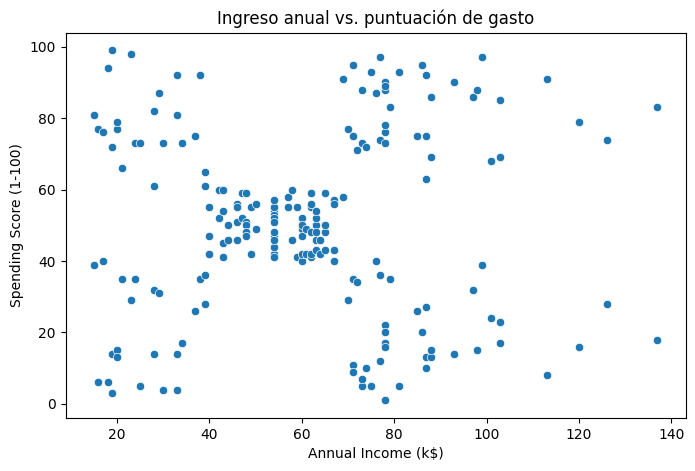

Coeficiente de correlación: 0.009902848094037651


In [15]:
# tu código aquí
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)'
)
plt.title('Ingreso anual vs. puntuación de gasto')
plt.show()

correlacion = df['Annual Income (k$)'].corr(
    df['Spending Score (1-100)']
)

print('Coeficiente de correlación:', correlacion)

### 5. ¿Cómo varía la puntuación de gasto en diferentes grupos de ingresos anuales?
- **Objetivo**: Examinar cómo los clientes en diferentes rangos de ingresos se comportan en términos de gasto.
- **Respuesta esperada**: Una gráfica de cajas o de violín que muestre la Spending Score (1-100) para diferentes rangos de Annual Income (k$).

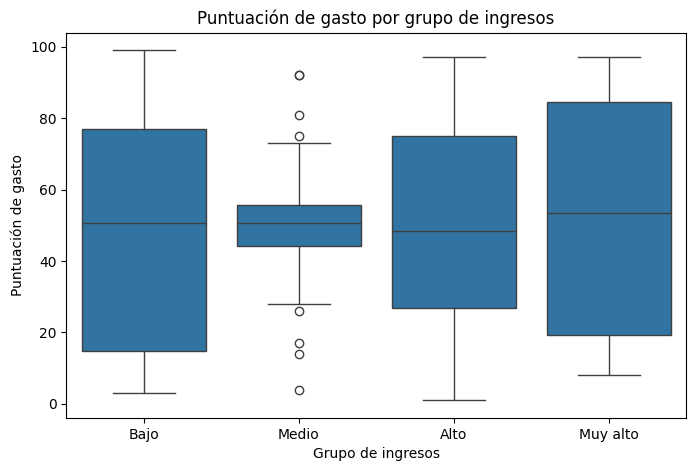

In [16]:
# tu código aquí
df['Income Group'] = pd.cut(
    df['Annual Income (k$)'],
    bins=[0, 30, 60, 90, float('inf')],
    labels=['Bajo', 'Medio', 'Alto', 'Muy alto']
)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Income Group', y='Spending Score (1-100)')
plt.title('Puntuación de gasto por grupo de ingresos')
plt.xlabel('Grupo de ingresos')
plt.ylabel('Puntuación de gasto')
plt.show()

### 6. ¿Cuál es la proporción de clientes por género?
- **Objetivo**: Determinar el balance de género en el conjunto de datos.
- **Respuesta esperada**: Una gráfica de barras o un gráfico de pastel que muestre la proporción de hombres y mujeres.

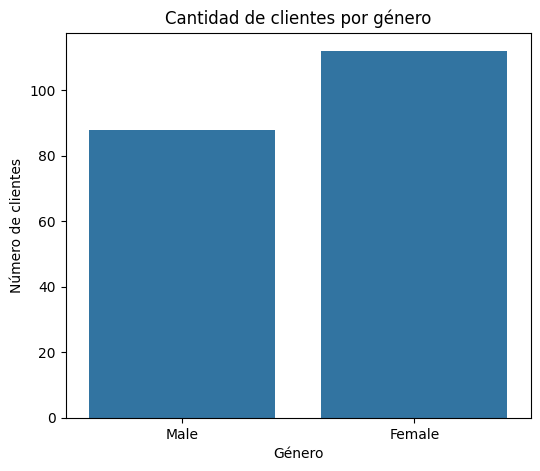

Gender
Female    56.0
Male      44.0
Name: proportion, dtype: float64


In [17]:
# tu código aquí
plt.figure(figsize=(6, 5))
sns.countplot(data=df, x='Gender')
plt.title('Cantidad de clientes por género')
plt.xlabel('Género')
plt.ylabel('Número de clientes')
plt.show()

print(df['Gender'].value_counts(normalize=True) * 100)

### 7. ¿Qué grupos de edad gastan más en promedio?
- **Objetivo**: Identificar los grupos de edad que tienen una mayor puntuación de gasto en promedio.
- **Respuesta esperada**: Una gráfica de barras que compare la puntuación de gasto promedio entre diferentes grupos de edad.

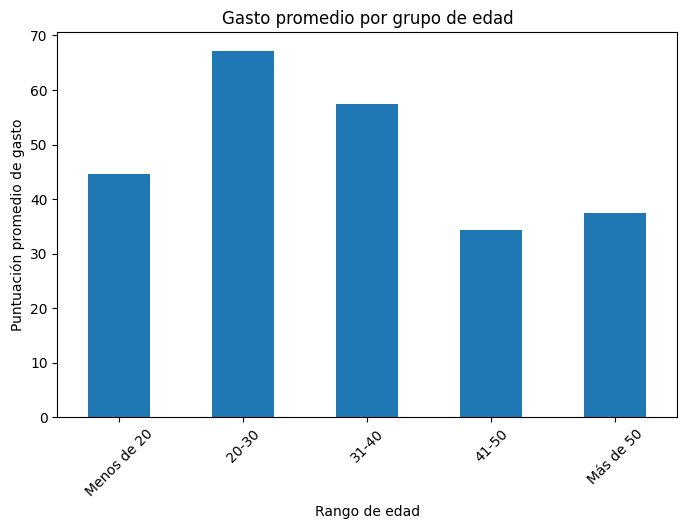

Age Group
20-30          67.222222
31-40          57.500000
Menos de 20    44.647059
Más de 50      37.475000
41-50          34.394737
Name: Spending Score (1-100), dtype: float64


In [18]:
# tu código aquí
gasto_promedio = df.groupby(
    'Age Group',
    observed=False
)['Spending Score (1-100)'].mean()

gasto_promedio.plot(kind='bar', figsize=(8, 5))

plt.title('Gasto promedio por grupo de edad')
plt.xlabel('Rango de edad')
plt.ylabel('Puntuación promedio de gasto')
plt.xticks(rotation=45)
plt.show()

print(gasto_promedio.sort_values(ascending=False))

### 8. ¿Hay alguna relación entre la edad y el ingreso anual de los clientes?
- **Objetivo**: Explorar si hay una tendencia entre la edad de los clientes y sus ingresos.
- **Respuesta esperada**: Una gráfica de dispersión que muestre la relación entre Age y Annual Income (k$).

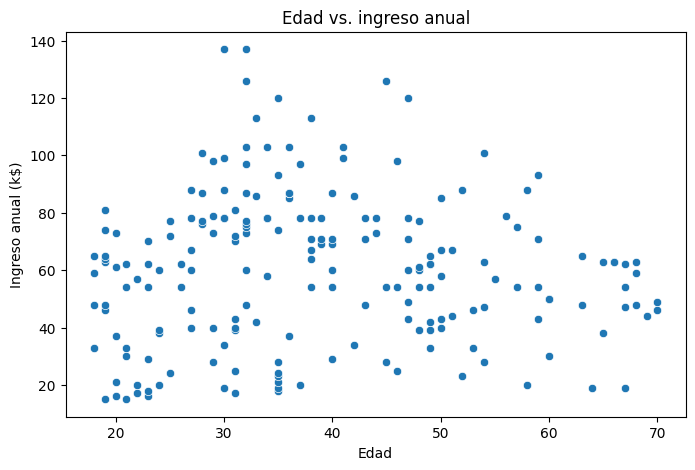

In [19]:
# tu código aquí
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Age', y='Annual Income (k$)')
plt.title('Edad vs. ingreso anual')
plt.xlabel('Edad')
plt.ylabel('Ingreso anual (k$)')
plt.show()

### 9. ¿Cuál es la distribución conjunta de la edad y el ingreso anual?
- **Objetivo**: Entender cómo se distribuyen estas dos variables en conjunto.
- **Respuesta esperada**: Una gráfica de dispersión con una densidad de puntos o un gráfico de hexágonos que muestre la distribución conjunta de Age y Annual Income (k$).

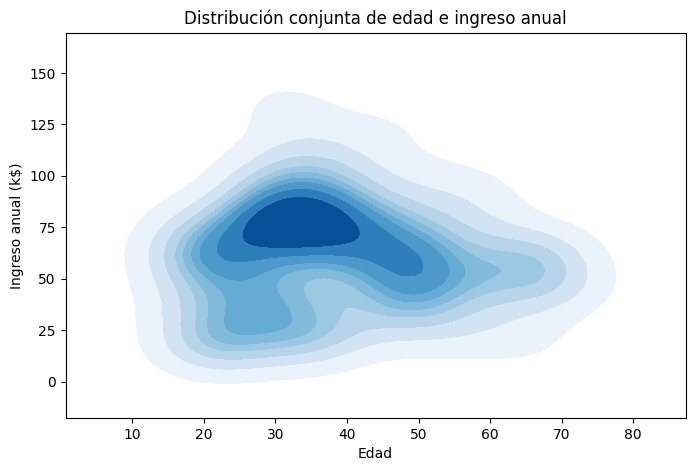

In [20]:
# tu código aquí
plt.figure(figsize=(8, 5))
sns.kdeplot(
    data=df,
    x='Age',
    y='Annual Income (k$)',
    fill=True,
    cmap='Blues'
)
plt.title('Distribución conjunta de edad e ingreso anual')
plt.xlabel('Edad')
plt.ylabel('Ingreso anual (k$)')
plt.show()

### 10. ¿Cómo se distribuyen los clientes en función de la puntuación de gasto y el género?
- **Objetivo**: Analizar la relación entre la puntuación de gasto y el género.
- **Respuesta esperada**: Una gráfica de dispersión o un gráfico de violín que muestre la Spending Score (1-100) separada por género.

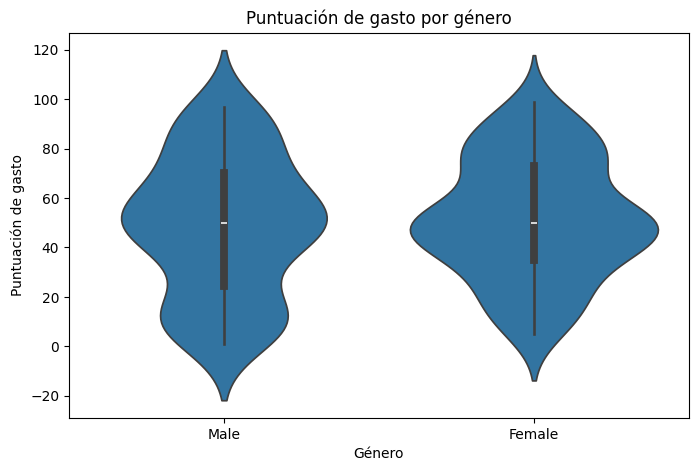

In [21]:
# tu código aquí
plt.figure(figsize=(8, 5))
sns.violinplot(
    data=df,
    x='Gender',
    y='Spending Score (1-100)'
)
plt.title('Puntuación de gasto por género')
plt.xlabel('Género')
plt.ylabel('Puntuación de gasto')
plt.show()